# MRI Visualization: Image + Catheter + Artifact Masks
## Single Subject Analysis

This notebook visualizes:
- Original MRI volume
- Catheter segmentation mask
- Artifact segmentation mask
- Overlays and 3D views

In [1]:
# Import libraries
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib import gridspec
from mpl_toolkits.mplot3d import Axes3D
from scipy import ndimage
import warnings
warnings.filterwarnings('ignore')

# For better visualization
plt.rcParams['figure.dpi'] = 100
plt.rcParams['savefig.dpi'] = 150

print("✓ Libraries imported successfully")

✓ Libraries imported successfully


## 1. Configuration

In [2]:
# ============================================================================
# UPDATE THESE PATHS TO YOUR FILES
# ============================================================================

# Path to MRI image
IMAGE_PATH = "data/Train/subj194/subj194_image.nii.gz"

# Path to catheter mask
CATHETER_MASK_PATH = "data/Train/subj194/subj194_catheter.nii.gz"

# Path to artifact mask
ARTIFACT_MASK_PATH = "data/Train/subj194/subj194_artifact.nii.gz"

# Or set to None if you don't have separate masks
# CATHETER_MASK_PATH = None
# ARTIFACT_MASK_PATH = None

print("Configuration set!")
print(f"Image: {IMAGE_PATH}")
print(f"Catheter mask: {CATHETER_MASK_PATH}")
print(f"Artifact mask: {ARTIFACT_MASK_PATH}")

Configuration set!
Image: data/Train/subj194/subj194_image.nii.gz
Catheter mask: data/Train/subj194/subj194_catheter.nii.gz
Artifact mask: data/Train/subj194/subj194_artifact.nii.gz


## 2. Load Data

In [3]:
# Load MRI image
print("Loading MRI image...")
img_nii = nib.load(IMAGE_PATH)
img_data = img_nii.get_fdata()
spacing = img_nii.header.get_zooms()[:3]
affine = img_nii.affine

print(f"✓ Image loaded:")
print(f"  Shape: {img_data.shape}")
print(f"  Spacing: {spacing} mm")
print(f"  Data type: {img_data.dtype}")
print(f"  Intensity range: [{img_data.min():.1f}, {img_data.max():.1f}]")

# Load catheter mask
catheter_data = None
if CATHETER_MASK_PATH:
    print("\nLoading catheter mask...")
    catheter_nii = nib.load(CATHETER_MASK_PATH)
    catheter_data = catheter_nii.get_fdata()
    n_catheter_voxels = np.sum(catheter_data > 0)
    catheter_volume_mm3 = n_catheter_voxels * np.prod(spacing)
    print(f"✓ Catheter mask loaded:")
    print(f"  Positive voxels: {n_catheter_voxels:,}")
    print(f"  Volume: {catheter_volume_mm3/1000:.2f} cm³")

# Load artifact mask
artifact_data = None
if ARTIFACT_MASK_PATH:
    print("\nLoading artifact mask...")
    artifact_nii = nib.load(ARTIFACT_MASK_PATH)
    artifact_data = artifact_nii.get_fdata()
    n_artifact_voxels = np.sum(artifact_data > 0)
    artifact_volume_mm3 = n_artifact_voxels * np.prod(spacing)
    print(f"✓ Artifact mask loaded:")
    print(f"  Positive voxels: {n_artifact_voxels:,}")
    print(f"  Volume: {artifact_volume_mm3/1000:.2f} cm³")

print("\n" + "="*50)
print("All data loaded successfully!")
print("="*50)

Loading MRI image...
✓ Image loaded:
  Shape: (192, 224, 192)
  Spacing: (np.float32(1.0), np.float32(1.0), np.float32(1.0)) mm
  Data type: float64
  Intensity range: [0.0, 446.6]

Loading catheter mask...
✓ Catheter mask loaded:
  Positive voxels: 1,086
  Volume: 1.09 cm³

Loading artifact mask...
✓ Artifact mask loaded:
  Positive voxels: 12,838
  Volume: 12.84 cm³

All data loaded successfully!


## 3. Basic Image Statistics

In [4]:
# Calculate intensity percentiles for better visualization
nonzero_img = img_data[img_data > 0]

if len(nonzero_img) > 0:
    vmin_1, vmax_99 = np.percentile(nonzero_img, [1, 99])
    vmin_5, vmax_95 = np.percentile(nonzero_img, [5, 95])
    
    print("Intensity Statistics (non-zero voxels):")
    print(f"  Mean: {nonzero_img.mean():.2f}")
    print(f"  Std:  {nonzero_img.std():.2f}")
    print(f"  Median: {np.median(nonzero_img):.2f}")
    print(f"  1-99 percentile: [{vmin_1:.2f}, {vmax_99:.2f}]")
    print(f"  5-95 percentile: [{vmin_5:.2f}, {vmax_95:.2f}]")
else:
    vmin_1, vmax_99 = img_data.min(), img_data.max()

# Find center of mass for masks if available
if catheter_data is not None and np.sum(catheter_data > 0) > 0:
    catheter_com = ndimage.center_of_mass(catheter_data)
    print(f"\nCatheter center of mass: ({catheter_com[0]:.1f}, {catheter_com[1]:.1f}, {catheter_com[2]:.1f})")

if artifact_data is not None and np.sum(artifact_data > 0) > 0:
    artifact_com = ndimage.center_of_mass(artifact_data)
    print(f"Artifact center of mass: ({artifact_com[0]:.1f}, {artifact_com[1]:.1f}, {artifact_com[2]:.1f})")

Intensity Statistics (non-zero voxels):
  Mean: 62.78
  Std:  73.36
  Median: 14.98
  1-99 percentile: [1.15, 264.60]
  5-95 percentile: [1.99, 196.42]

Catheter center of mass: (150.5, 134.0, 71.1)
Artifact center of mass: (169.4, 129.3, 66.7)


## 4. Orthogonal Views (Sagittal, Coronal, Axial)

Using catheter center for slicing: (150, 133, 129)


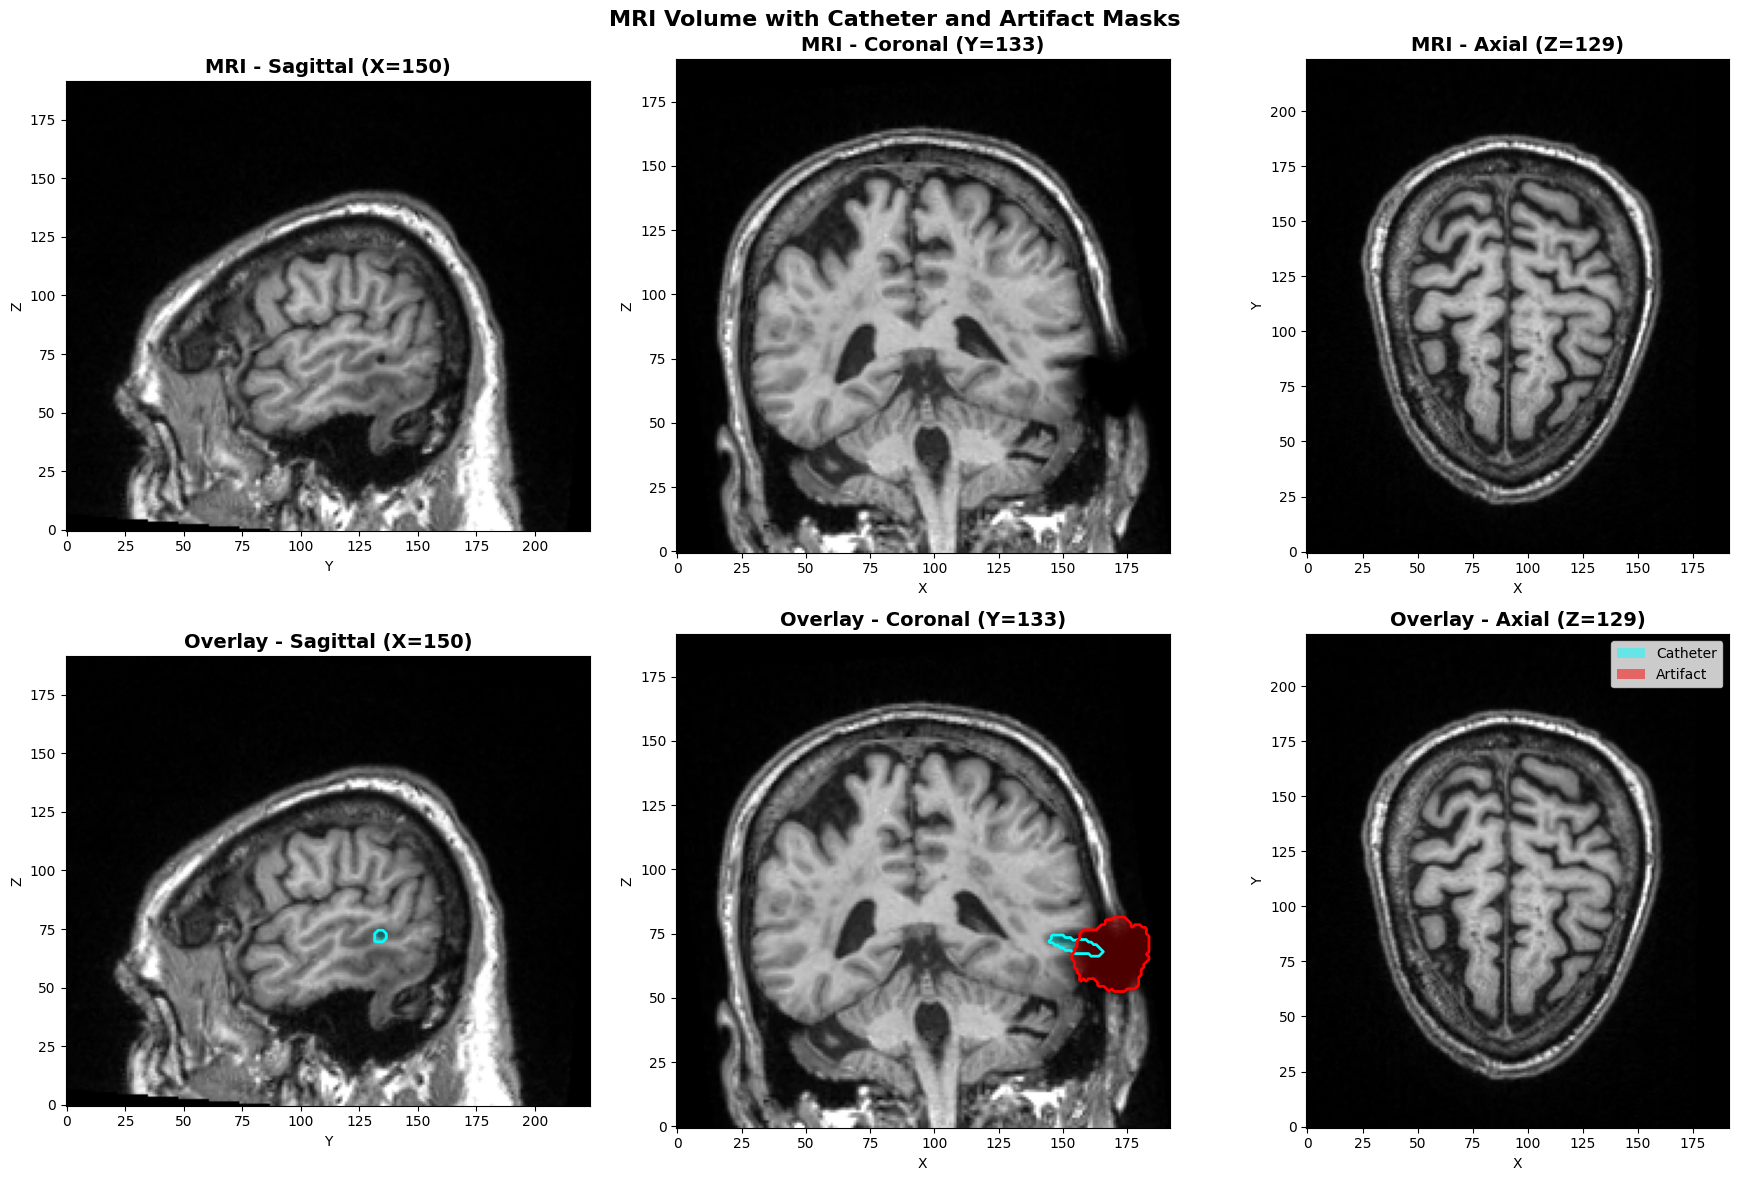


✓ Orthogonal views displayed


In [7]:
# Get center slices
center_x = img_data.shape[0] // 2
center_y = img_data.shape[1] // 2
center_z = 129 #img_data.shape[2] // 2

# If masks exist, use their center of mass for better visualization
if catheter_data is not None and np.sum(catheter_data > 0) > 0:
    com = ndimage.center_of_mass(catheter_data)
    center_x = int(com[0])
    center_y = int(com[1])
    # center_z = int(com[2])
    print(f"Using catheter center for slicing: ({center_x}, {center_y}, {center_z})")
elif artifact_data is not None and np.sum(artifact_data > 0) > 0:
    com = ndimage.center_of_mass(artifact_data)
    center_x = int(com[0])
    center_y = int(com[1])
    # center_z = int(com[2])
    print(f"Using artifact center for slicing: ({center_x}, {center_y}, {center_z})")

# Create figure
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# Row 1: MRI only
# Sagittal
axes[0, 0].imshow(img_data[center_x, :, :].T, cmap='gray', vmin=vmin_1, vmax=vmax_99, origin='lower')
axes[0, 0].set_title(f'MRI - Sagittal (X={center_x})', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Y')
axes[0, 0].set_ylabel('Z')

# Coronal
axes[0, 1].imshow(img_data[:, center_y, :].T, cmap='gray', vmin=vmin_1, vmax=vmax_99, origin='lower')
axes[0, 1].set_title(f'MRI - Coronal (Y={center_y})', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('X')
axes[0, 1].set_ylabel('Z')

# Axial
axes[0, 2].imshow(img_data[:, :, center_z].T, cmap='gray', vmin=vmin_1, vmax=vmax_99, origin='lower')
axes[0, 2].set_title(f'MRI - Axial (Z={center_z})', fontsize=14, fontweight='bold')
axes[0, 2].set_xlabel('X')
axes[0, 2].set_ylabel('Y')

# Row 2: MRI with masks overlay
# Sagittal with overlay
axes[1, 0].imshow(img_data[center_x, :, :].T, cmap='gray', vmin=vmin_1, vmax=vmax_99, origin='lower')
if catheter_data is not None:
    catheter_slice = catheter_data[center_x, :, :].T
    if catheter_slice.max() > 0:
        axes[1, 0].contour(catheter_slice, levels=[0.5], colors='cyan', linewidths=2, linestyles='solid')
        axes[1, 0].contourf(catheter_slice, levels=[0.5, 1], colors='cyan', alpha=0.3)
if artifact_data is not None:
    artifact_slice = artifact_data[center_x, :, :].T
    if artifact_slice.max() > 0:
        axes[1, 0].contour(artifact_slice, levels=[0.5], colors='red', linewidths=2, linestyles='solid')
        axes[1, 0].contourf(artifact_slice, levels=[0.5, 1], colors='red', alpha=0.3)
axes[1, 0].set_title(f'Overlay - Sagittal (X={center_x})', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Y')
axes[1, 0].set_ylabel('Z')

# Coronal with overlay
axes[1, 1].imshow(img_data[:, center_y, :].T, cmap='gray', vmin=vmin_1, vmax=vmax_99, origin='lower')
if catheter_data is not None:
    catheter_slice = catheter_data[:, center_y, :].T
    if catheter_slice.max() > 0:
        axes[1, 1].contour(catheter_slice, levels=[0.5], colors='cyan', linewidths=2, linestyles='solid')
        axes[1, 1].contourf(catheter_slice, levels=[0.5, 1], colors='cyan', alpha=0.3)
if artifact_data is not None:
    artifact_slice = artifact_data[:, center_y, :].T
    if artifact_slice.max() > 0:
        axes[1, 1].contour(artifact_slice, levels=[0.5], colors='red', linewidths=2, linestyles='solid')
        axes[1, 1].contourf(artifact_slice, levels=[0.5, 1], colors='red', alpha=0.3)
axes[1, 1].set_title(f'Overlay - Coronal (Y={center_y})', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('X')
axes[1, 1].set_ylabel('Z')

# Axial with overlay
axes[1, 2].imshow(img_data[:, :, center_z].T, cmap='gray', vmin=vmin_1, vmax=vmax_99, origin='lower')
if catheter_data is not None:
    catheter_slice = catheter_data[:, :, center_z].T
    if catheter_slice.max() > 0:
        axes[1, 2].contour(catheter_slice, levels=[0.5], colors='cyan', linewidths=2, linestyles='solid')
        axes[1, 2].contourf(catheter_slice, levels=[0.5, 1], colors='cyan', alpha=0.3)
if artifact_data is not None:
    artifact_slice = artifact_data[:, :, center_z].T
    if artifact_slice.max() > 0:
        axes[1, 2].contour(artifact_slice, levels=[0.5], colors='red', linewidths=2, linestyles='solid')
        axes[1, 2].contourf(artifact_slice, levels=[0.5, 1], colors='red', alpha=0.3)
axes[1, 2].set_title(f'Overlay - Axial (Z={center_z})', fontsize=14, fontweight='bold')
axes[1, 2].set_xlabel('X')
axes[1, 2].set_ylabel('Y')

# Add legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='cyan', alpha=0.5, label='Catheter'),
                   Patch(facecolor='red', alpha=0.5, label='Artifact')]
axes[1, 2].legend(handles=legend_elements, loc='upper right', fontsize=10)

plt.suptitle('MRI Volume with Catheter and Artifact Masks', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n✓ Orthogonal views displayed")

## 5. Multi-Slice Axial View (Movie-like)

In [6]:
# Show multiple consecutive axial slices
n_slices = 12
start_slice = max(0, center_z - n_slices//2)
end_slice = min(img_data.shape[2], center_z + n_slices//2)
slice_indices = np.linspace(start_slice, end_slice, n_slices, dtype=int)

fig, axes = plt.subplots(3, 4, figsize=(20, 15))
axes = axes.flatten()

for i, slice_idx in enumerate(slice_indices):
    # Show MRI
    axes[i].imshow(img_data[:, :, slice_idx].T, cmap='gray', vmin=vmin_1, vmax=vmax_99, origin='lower')
    
    # Overlay catheter
    if catheter_data is not None:
        catheter_slice = catheter_data[:, :, slice_idx].T
        if catheter_slice.max() > 0:
            axes[i].contour(catheter_slice, levels=[0.5], colors='cyan', linewidths=2)
    
    # Overlay artifact
    if artifact_data is not None:
        artifact_slice = artifact_data[:, :, slice_idx].T
        if artifact_slice.max() > 0:
            axes[i].contour(artifact_slice, levels=[0.5], colors='red', linewidths=2)
    
    axes[i].set_title(f'Axial Slice Z={slice_idx}', fontsize=12, fontweight='bold')
    axes[i].axis('off')

plt.suptitle('Multi-Slice Axial View (Cyan=Catheter, Red=Artifact)', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"\n✓ Displayed {n_slices} axial slices from Z={start_slice} to Z={end_slice}")

NameError: name 'center_z' is not defined

## 6. Mask-Only Visualization

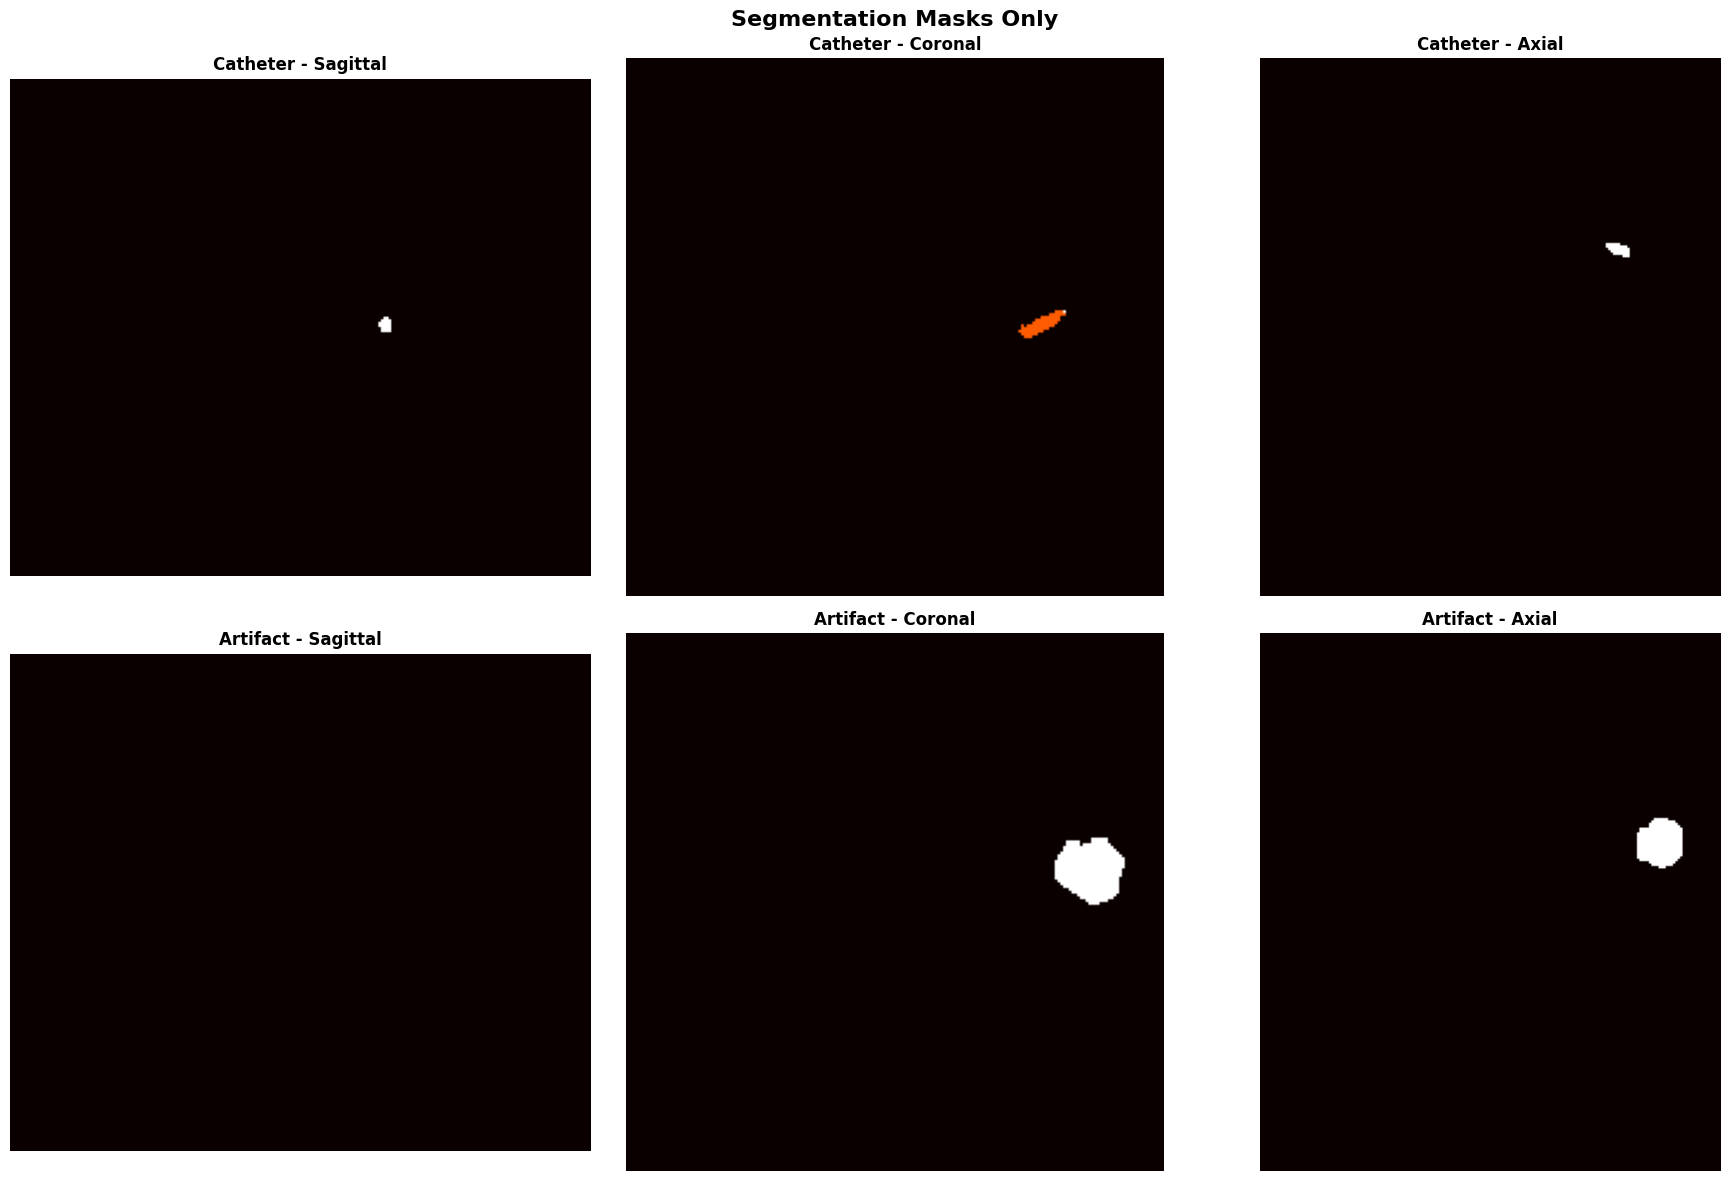


✓ Mask-only visualization displayed


In [11]:
# Show just the masks to see their structure clearly
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# Catheter masks
if catheter_data is not None:
    axes[0, 0].imshow(catheter_data[center_x, :, :].T, cmap='hot', origin='lower')
    axes[0, 0].set_title('Catheter - Sagittal', fontsize=12, fontweight='bold')
    axes[0, 0].axis('off')
    
    axes[0, 1].imshow(catheter_data[:, center_y, :].T, cmap='hot', origin='lower')
    axes[0, 1].set_title('Catheter - Coronal', fontsize=12, fontweight='bold')
    axes[0, 1].axis('off')
    
    axes[0, 2].imshow(catheter_data[:, :, center_z].T, cmap='hot', origin='lower')
    axes[0, 2].set_title('Catheter - Axial', fontsize=12, fontweight='bold')
    axes[0, 2].axis('off')
else:
    for ax in axes[0, :]:
        ax.text(0.5, 0.5, 'No catheter mask', ha='center', va='center', fontsize=14)
        ax.axis('off')

# Artifact masks
if artifact_data is not None:
    axes[1, 0].imshow(artifact_data[center_x, :, :].T, cmap='hot', origin='lower')
    axes[1, 0].set_title('Artifact - Sagittal', fontsize=12, fontweight='bold')
    axes[1, 0].axis('off')
    
    axes[1, 1].imshow(artifact_data[:, center_y, :].T, cmap='hot', origin='lower')
    axes[1, 1].set_title('Artifact - Coronal', fontsize=12, fontweight='bold')
    axes[1, 1].axis('off')
    
    axes[1, 2].imshow(artifact_data[:, :, center_z].T, cmap='hot', origin='lower')
    axes[1, 2].set_title('Artifact - Axial', fontsize=12, fontweight='bold')
    axes[1, 2].axis('off')
else:
    for ax in axes[1, :]:
        ax.text(0.5, 0.5, 'No artifact mask', ha='center', va='center', fontsize=14)
        ax.axis('off')

plt.suptitle('Segmentation Masks Only', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n✓ Mask-only visualization displayed")

## 7. 3D Surface Rendering

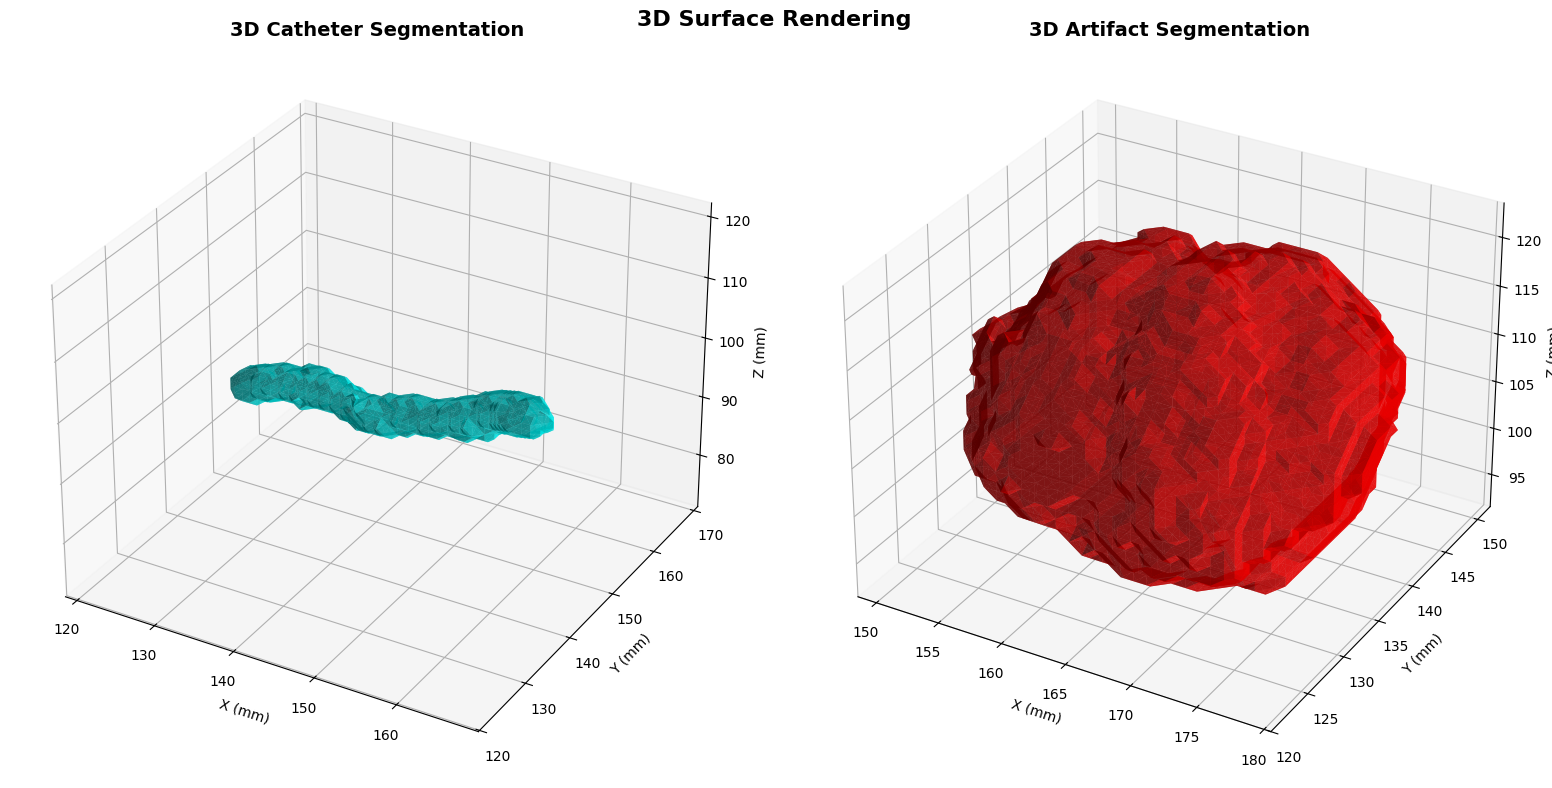


✓ 3D surface rendering complete


In [12]:
from skimage import measure

fig = plt.figure(figsize=(16, 8))

# 3D rendering of catheter
if catheter_data is not None and np.sum(catheter_data > 0) > 0:
    ax1 = fig.add_subplot(121, projection='3d')
    
    # Create surface mesh
    verts, faces, _, _ = measure.marching_cubes(catheter_data, level=0.5)
    
    # Apply spacing for proper aspect ratio
    verts_scaled = verts * spacing
    
    ax1.plot_trisurf(verts_scaled[:, 0], verts_scaled[:, 1], faces, verts_scaled[:, 2],
                     color='cyan', alpha=0.7, edgecolor='none')
    
    ax1.set_xlabel('X (mm)', fontsize=10)
    ax1.set_ylabel('Y (mm)', fontsize=10)
    ax1.set_zlabel('Z (mm)', fontsize=10)
    ax1.set_title('3D Catheter Segmentation', fontsize=14, fontweight='bold')
    
    # Equal aspect ratio
    max_range = np.array([verts_scaled[:, 0].max()-verts_scaled[:, 0].min(),
                         verts_scaled[:, 1].max()-verts_scaled[:, 1].min(),
                         verts_scaled[:, 2].max()-verts_scaled[:, 2].min()]).max() / 2.0
    
    mid_x = (verts_scaled[:, 0].max()+verts_scaled[:, 0].min()) * 0.5
    mid_y = (verts_scaled[:, 1].max()+verts_scaled[:, 1].min()) * 0.5
    mid_z = (verts_scaled[:, 2].max()+verts_scaled[:, 2].min()) * 0.5
    
    ax1.set_xlim(mid_x - max_range, mid_x + max_range)
    ax1.set_ylim(mid_y - max_range, mid_y + max_range)
    ax1.set_zlim(mid_z - max_range, mid_z + max_range)

# 3D rendering of artifact
if artifact_data is not None and np.sum(artifact_data > 0) > 0:
    ax2 = fig.add_subplot(122, projection='3d')
    
    # Create surface mesh
    verts, faces, _, _ = measure.marching_cubes(artifact_data, level=0.5)
    
    # Apply spacing for proper aspect ratio
    verts_scaled = verts * spacing
    
    ax2.plot_trisurf(verts_scaled[:, 0], verts_scaled[:, 1], faces, verts_scaled[:, 2],
                     color='red', alpha=0.7, edgecolor='none')
    
    ax2.set_xlabel('X (mm)', fontsize=10)
    ax2.set_ylabel('Y (mm)', fontsize=10)
    ax2.set_zlabel('Z (mm)', fontsize=10)
    ax2.set_title('3D Artifact Segmentation', fontsize=14, fontweight='bold')
    
    # Equal aspect ratio
    max_range = np.array([verts_scaled[:, 0].max()-verts_scaled[:, 0].min(),
                         verts_scaled[:, 1].max()-verts_scaled[:, 1].min(),
                         verts_scaled[:, 2].max()-verts_scaled[:, 2].min()]).max() / 2.0
    
    mid_x = (verts_scaled[:, 0].max()+verts_scaled[:, 0].min()) * 0.5
    mid_y = (verts_scaled[:, 1].max()+verts_scaled[:, 1].min()) * 0.5
    mid_z = (verts_scaled[:, 2].max()+verts_scaled[:, 2].min()) * 0.5
    
    ax2.set_xlim(mid_x - max_range, mid_x + max_range)
    ax2.set_ylim(mid_y - max_range, mid_y + max_range)
    ax2.set_zlim(mid_z - max_range, mid_z + max_range)

plt.suptitle('3D Surface Rendering', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n✓ 3D surface rendering complete")

## 8. Interactive Slice Viewer (Use slider to navigate)

In [ ]:
from ipywidgets import interact, IntSlider, Dropdown

def view_slice_multi(axis_name, slice_idx):
    """Interactive slice viewer supporting Axial, Coronal, and Sagittal views"""
    # Mapping axis names to indices
    axis_map = {'Sagittal (L-R)': 0, 'Coronal (A-P)': 1, 'Axial (S-I)': 2}
    axis = axis_map[axis_name]
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    
    # Helper to extract the slice correctly based on axis
    def get_slice(volume, idx, ax):
        if volume is None: return None
        if ax == 0: return volume[idx, :, :].T
        if ax == 1: return volume[:, idx, :].T
        if ax == 2: return volume[:, :, idx].T
        return None

    img_slice = get_slice(img_data, slice_idx, axis)
    
    # Set titles and plot
    titles = [f'MRI ({axis_name})', 'MRI + Catheter', 'MRI + Artifact']
    
    for i in range(3):
        axes[i].imshow(img_slice, cmap='gray', vmin=vmin_1, vmax=vmax_99, origin='lower')
        axes[i].axis('off')
        
    # Overlay Catheter (Cyan)
    if catheter_data is not None:
        c_slice = get_slice(catheter_data, slice_idx, axis)
        if c_slice.max() > 0:
            axes[1].contour(c_slice, levels=[0.5], colors='cyan', linewidths=2)
            axes[1].contourf(c_slice, levels=[0.5, 1], colors='cyan', alpha=0.3)
            
    # Overlay Artifact (Red)
    if artifact_data is not None:
        a_slice = get_slice(artifact_data, slice_idx, axis)
        if a_slice.max() > 0:
            axes[2].contour(a_slice, levels=[0.5], colors='red', linewidths=2)
            axes[2].contourf(a_slice, levels=[0.5, 1], colors='red', alpha=0.3)

    for i, title in enumerate(titles):
        axes[i].set_title(f"{title} - Slice {slice_idx}", fontsize=12, fontweight='bold')
        
    plt.tight_layout()
    plt.show()

# Update slider max value dynamically based on chosen axis
def update_view(axis_name):
    axis_map = {'Sagittal (L-R)': 0, 'Coronal (A-P)': 1, 'Axial (S-I)': 2}
    max_val = img_data.shape[axis_map[axis_name]] - 1
    
    interact(view_slice_multi, 
             axis_name=Dropdown(options=['Axial (S-I)', 'Coronal (A-P)', 'Sagittal (L-R)'], value=axis_name),
             slice_idx=IntSlider(min=0, max=max_val, step=1, value=max_val//2, continuous_update=False))

update_view('Axial (S-I)')

interactive(children=(Dropdown(description='axis_name', options=('Axial (S-I)', 'Coronal (A-P)', 'Sagittal (L-…

## 9. Intensity Analysis Around Masks

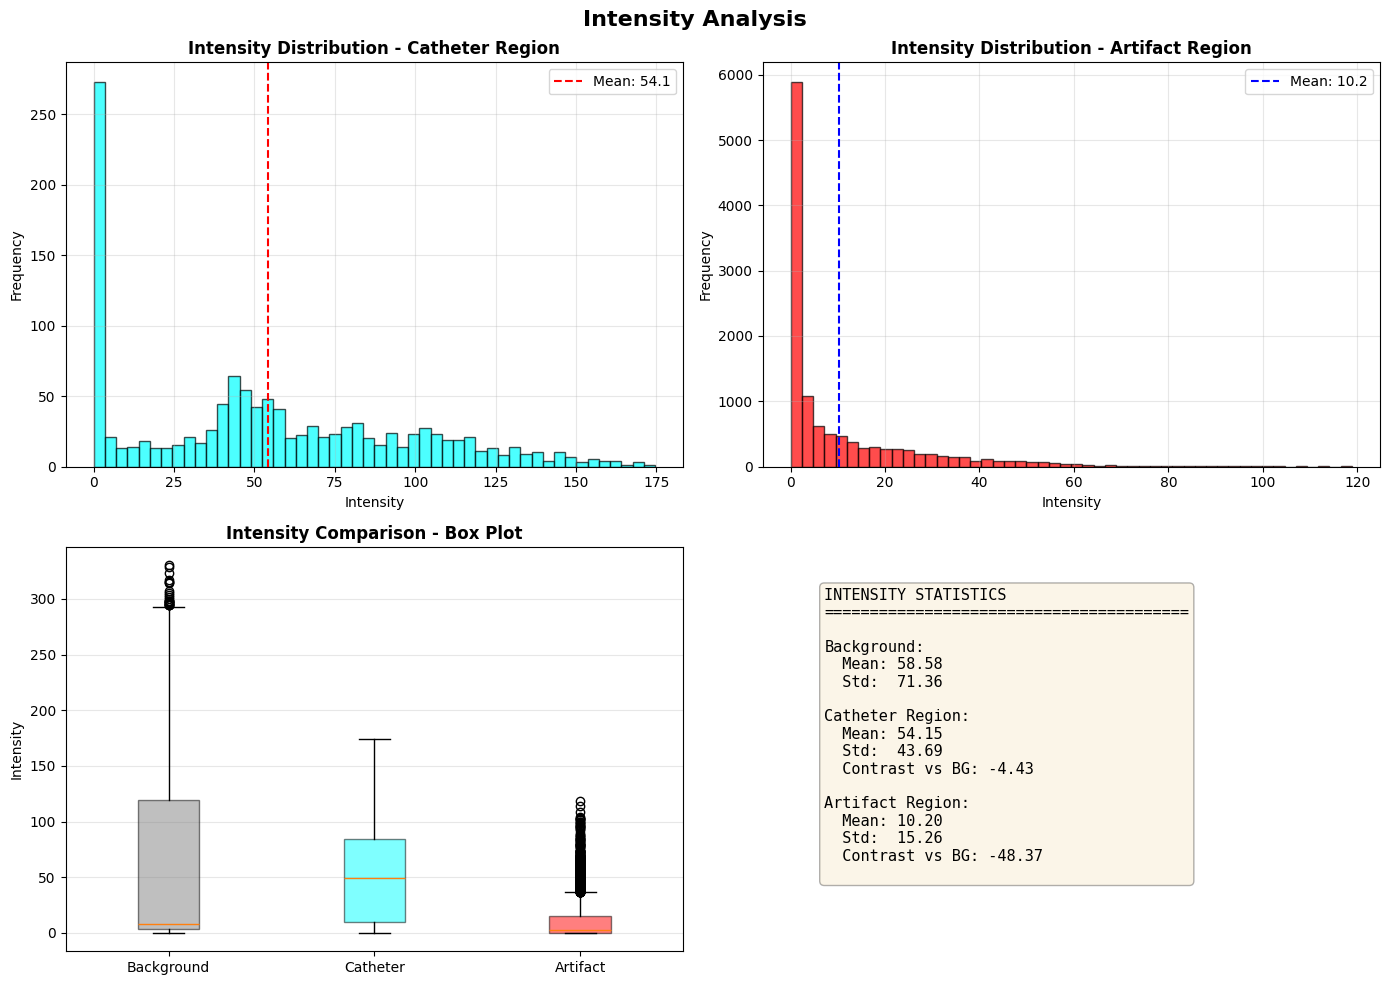


✓ Intensity analysis complete


In [11]:
# Analyze intensity characteristics around catheter and artifact
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Catheter intensity distribution
if catheter_data is not None and np.sum(catheter_data > 0) > 0:
    catheter_intensities = img_data[catheter_data > 0]
    axes[0, 0].hist(catheter_intensities, bins=50, color='cyan', alpha=0.7, edgecolor='black')
    axes[0, 0].set_xlabel('Intensity', fontsize=10)
    axes[0, 0].set_ylabel('Frequency', fontsize=10)
    axes[0, 0].set_title('Intensity Distribution - Catheter Region', fontsize=12, fontweight='bold')
    axes[0, 0].axvline(catheter_intensities.mean(), color='red', linestyle='--', 
                      label=f'Mean: {catheter_intensities.mean():.1f}')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)

# Artifact intensity distribution
if artifact_data is not None and np.sum(artifact_data > 0) > 0:
    artifact_intensities = img_data[artifact_data > 0]
    axes[0, 1].hist(artifact_intensities, bins=50, color='red', alpha=0.7, edgecolor='black')
    axes[0, 1].set_xlabel('Intensity', fontsize=10)
    axes[0, 1].set_ylabel('Frequency', fontsize=10)
    axes[0, 1].set_title('Intensity Distribution - Artifact Region', fontsize=12, fontweight='bold')
    axes[0, 1].axvline(artifact_intensities.mean(), color='blue', linestyle='--',
                      label=f'Mean: {artifact_intensities.mean():.1f}')
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3)

# Background vs catheter vs artifact comparison
background_intensities = img_data[(catheter_data == 0) & (artifact_data == 0) & (img_data > 0)]
if len(background_intensities) > 1000:
    background_intensities = np.random.choice(background_intensities, 10000, replace=False)

data_to_plot = []
labels = []
colors = []

if len(background_intensities) > 0:
    data_to_plot.append(background_intensities)
    labels.append('Background')
    colors.append('gray')

if catheter_data is not None and np.sum(catheter_data > 0) > 0:
    data_to_plot.append(catheter_intensities)
    labels.append('Catheter')
    colors.append('cyan')

if artifact_data is not None and np.sum(artifact_data > 0) > 0:
    data_to_plot.append(artifact_intensities)
    labels.append('Artifact')
    colors.append('red')

bp = axes[1, 0].boxplot(data_to_plot, labels=labels, patch_artist=True)
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.5)
axes[1, 0].set_ylabel('Intensity', fontsize=10)
axes[1, 0].set_title('Intensity Comparison - Box Plot', fontsize=12, fontweight='bold')
axes[1, 0].grid(True, alpha=0.3, axis='y')

# Statistics table
axes[1, 1].axis('off')
stats_text = "INTENSITY STATISTICS\n" + "="*40 + "\n\n"

stats_text += f"Background:\n"
stats_text += f"  Mean: {background_intensities.mean():.2f}\n"
stats_text += f"  Std:  {background_intensities.std():.2f}\n\n"

if catheter_data is not None and np.sum(catheter_data > 0) > 0:
    stats_text += f"Catheter Region:\n"
    stats_text += f"  Mean: {catheter_intensities.mean():.2f}\n"
    stats_text += f"  Std:  {catheter_intensities.std():.2f}\n"
    stats_text += f"  Contrast vs BG: {(catheter_intensities.mean() - background_intensities.mean()):.2f}\n\n"

if artifact_data is not None and np.sum(artifact_data > 0) > 0:
    stats_text += f"Artifact Region:\n"
    stats_text += f"  Mean: {artifact_intensities.mean():.2f}\n"
    stats_text += f"  Std:  {artifact_intensities.std():.2f}\n"
    stats_text += f"  Contrast vs BG: {(artifact_intensities.mean() - background_intensities.mean()):.2f}\n"

axes[1, 1].text(0.1, 0.9, stats_text, transform=axes[1, 1].transAxes,
               fontsize=11, verticalalignment='top', family='monospace',
               bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.3))

plt.suptitle('Intensity Analysis', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n✓ Intensity analysis complete")